# 01 — Data Understanding

Notebook ini merupakan bagian dari **Fase 2 CRISP-DM** pada penelitian
*Alert Reduction* untuk log Wazuh SOC INSTIKI.

**Tujuan:**
1. Memuat seluruh data log mentah dari `data/raw/`.
2. Melakukan *flattening* dan *cleaning* awal (sesuai `src/transformers.py`).
3. Mengaudit kualitas data: tipe, null, duplikat.
4. Eksplorasi distribusi fitur utama dan pola temporal.
5. Menyimpulkan karakteristik dataset sebagai dasar Data Preparation.

## 1. Setup & Import

In [30]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from config import (
    DATA_RAW_DIR,
    DATA_PROC_DIR,
    FIGURES_DIR,
    EXTRACT_FIELDS,
)
from src.transformers import read_wazuh_logs, flatten_and_clean_logs

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
DATA_PROC_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("✓ Setup selesai.")
print(f"  Raw data dir : {DATA_RAW_DIR}")
print(f"  Figures dir  : {FIGURES_DIR}")

✓ Setup selesai.
  Raw data dir : e:\Aditya\Lecture\TUGAS-AKHIR\wazuh-alert-reduction\data\raw
  Figures dir  : e:\Aditya\Lecture\TUGAS-AKHIR\wazuh-alert-reduction\reports\figures


## 2. Pemuatan Data Mentah

`read_wazuh_logs()` membaca semua `ossec-alerts-*.json.gz` dari arsip `.tar.gz`
maupun folder di `data/raw/`. Setiap record di-*flatten* sesuai `config.EXTRACT_FIELDS`.

In [31]:
print(f"Field yang diekstrak: {list(EXTRACT_FIELDS.keys())}\n")

raw_records = read_wazuh_logs(DATA_RAW_DIR)
print(f"Total record mentah terbaca: {len(raw_records):,}")

Field yang diekstrak: ['timestamp', 'agent_name', 'rule_level', 'rule_description', 'rule_id', 'rule_groups', 'decoder_name', 'location']

Total record mentah terbaca: 1,430,776


In [32]:
df_raw = pd.DataFrame(raw_records)
print(f"Shape DataFrame mentah: {df_raw.shape}")
print(f"Kolom: {list(df_raw.columns)}")
df_raw.head()

Shape DataFrame mentah: (1430776, 8)
Kolom: ['timestamp', 'agent_name', 'rule_level', 'rule_description', 'rule_id', 'rule_groups', 'decoder_name', 'location']


,timestamp,agent_name,rule_level,rule_description,rule_id,rule_groups,decoder_name,location
0,2025-09-15T00:00:09.125+0000,siput,3,Log file rotated.,591,[ossec],ossec,logcollector
1,2025-09-15T00:00:22.071+0000,sads,3,ClamAV database update,52507,"[clamd, freshclam, virus]",freshclam,journald
2,2025-09-15T00:00:30.677+0000,siput,3,ClamAV database update,52507,"[clamd, freshclam, virus]",freshclam,journald
3,2025-09-15T00:00:49.212+0000,proxy-manager,3,ClamAV database update,52507,"[clamd, freshclam, virus]",freshclam,journald
4,2025-09-15T00:00:59.094+0000,e-kuesioner,3,Log file rotated.,591,[ossec],ossec,logcollector


## 3. Cleaning & Flattening

`flatten_and_clean_logs()` melakukan:
- Drop baris dengan kolom kritis null.
- Konversi tipe data (`timestamp` → datetime, `rule_level` → int, dll.).
- Normalisasi `rule_groups` (list → string dipisah koma).

In [33]:
df = flatten_and_clean_logs(raw_records)

rows_removed = len(raw_records) - len(df)
pct_removed  = (rows_removed / len(raw_records)) * 100 if raw_records else 0

print(f"Baris sebelum cleaning : {len(raw_records):,}")
print(f"Baris setelah cleaning : {len(df):,}")
print(f"Baris dihapus          : {rows_removed:,} ({pct_removed:.2f}%)\n")
df.head()

Baris sebelum cleaning : 1,430,776
Baris setelah cleaning : 1,429,394
Baris dihapus          : 1,382 (0.10%)



,timestamp,agent_name,rule_level,rule_description,rule_id,rule_groups,decoder_name,location
0,2025-09-15 08:00:09.125,siput,3,Log file rotated.,591,ossec,ossec,logcollector
1,2025-09-15 08:00:22.071,sads,3,ClamAV database update,52507,"clamd,freshclam,virus",freshclam,journald
2,2025-09-15 08:00:30.677,siput,3,ClamAV database update,52507,"clamd,freshclam,virus",freshclam,journald
3,2025-09-15 08:00:49.212,proxy-manager,3,ClamAV database update,52507,"clamd,freshclam,virus",freshclam,journald
4,2025-09-15 08:00:59.094,e-kuesioner,3,Log file rotated.,591,ossec,ossec,logcollector


## 4. Audit Kualitas Data

### 4.1 Info & Tipe Data

In [34]:
df.info()

print("Tipe data per kolom:")
print(df.dtypes)
print()
print("Statistik deskriptif (kolom numerik):")
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1429394 entries, 0 to 1429393
Data columns (total 8 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   timestamp         1429394 non-null  datetime64[ns]
 1   agent_name        1429394 non-null  object        
 2   rule_level        1429394 non-null  int64         
 3   rule_description  1429394 non-null  object        
 4   rule_id           1429394 non-null  object        
 5   rule_groups       1429394 non-null  object        
 6   decoder_name      1429394 non-null  object        
 7   location          1429394 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(6)
memory usage: 87.2+ MB
Tipe data per kolom:
timestamp           datetime64[ns]
agent_name                  object
rule_level                   int64
rule_description            object
rule_id                     object
rule_groups                 object
decoder_name               

,timestamp,rule_level
count,1429394,1.429394e+06
mean,2025-10-04 11:46:24.141187072,5.633890e+00
min,2025-05-10 10:06:46.854000,3.000000e+00
25%,2025-06-16 22:27:34.665250048,5.000000e+00
50%,2025-09-09 10:22:21.768000,5.000000e+00
75%,2026-01-31 23:42:02.390000128,5.000000e+00
max,2026-04-02 07:59:05.013000,1.500000e+01
std,NaN,1.824326e+00


### 4.2 Pemeriksaan Null Values

In [35]:
null_counts = df_raw.isnull().sum()
null_pct    = (df_raw.isnull().mean() * 100).round(2)

null_audit = pd.DataFrame({
    "null_count": null_counts,
    "null_pct (%)": null_pct,
})
print("Audit Null Values (data mentah, sebelum cleaning):")
print(null_audit.to_string())
print()
print(f"Null values setelah cleaning: {df.isnull().sum().sum()}")

Audit Null Values (data mentah, sebelum cleaning):
                  null_count  null_pct (%)
timestamp                  0          0.00
agent_name                 0          0.00
rule_level                 0          0.00
rule_description         131          0.01
rule_id                    0          0.00
rule_groups                0          0.00
decoder_name            1382          0.10
location                   0          0.00

Null values setelah cleaning: 0


### 4.3 Pemeriksaan Baris Duplikat

In [36]:
n_exact_dup = df.duplicated().sum()
print(f"Jumlah baris duplikat persis: {n_exact_dup:,}")
print(f"Persentase duplikat: {(n_exact_dup / len(df) * 100):.2f}%")
print()
print("Catatan: deduplikasi temporal berbasis time-window dilakukan")
print("pada fase Data Preparation (notebook 02).")

Jumlah baris duplikat persis: 232,476
Persentase duplikat: 16.26%

Catatan: deduplikasi temporal berbasis time-window dilakukan
pada fase Data Preparation (notebook 02).


### 4.4 Kardinalitas Setiap Fitur

In [37]:
cardinality = df.nunique().reset_index()
cardinality.columns = ["kolom", "unique_count"]
print("Kardinalitas (jumlah nilai unik per kolom):")
print(cardinality.to_string(index=False))

Kardinalitas (jumlah nilai unik per kolom):
           kolom  unique_count
       timestamp       1173036
      agent_name             8
      rule_level            12
rule_description         84323
         rule_id           113
     rule_groups            59
    decoder_name            24
        location            20


## 5. Eksplorasi Distribusi Fitur

### 5.1 Distribusi per Agent (`agent_name`)

In [38]:
agent_dist = (
    df.groupby("agent_name")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Distribusi alert per agent:")
print(agent_dist.to_string(index=False))

Distribusi alert per agent:
   agent_name  alert_count
         sads       637082
   pusatkarir       277817
        siput       217831
  e-kuesioner       168842
    dfir-iris        54847
proxy-manager        35801
         DVWA        23832
        soc-1        13342


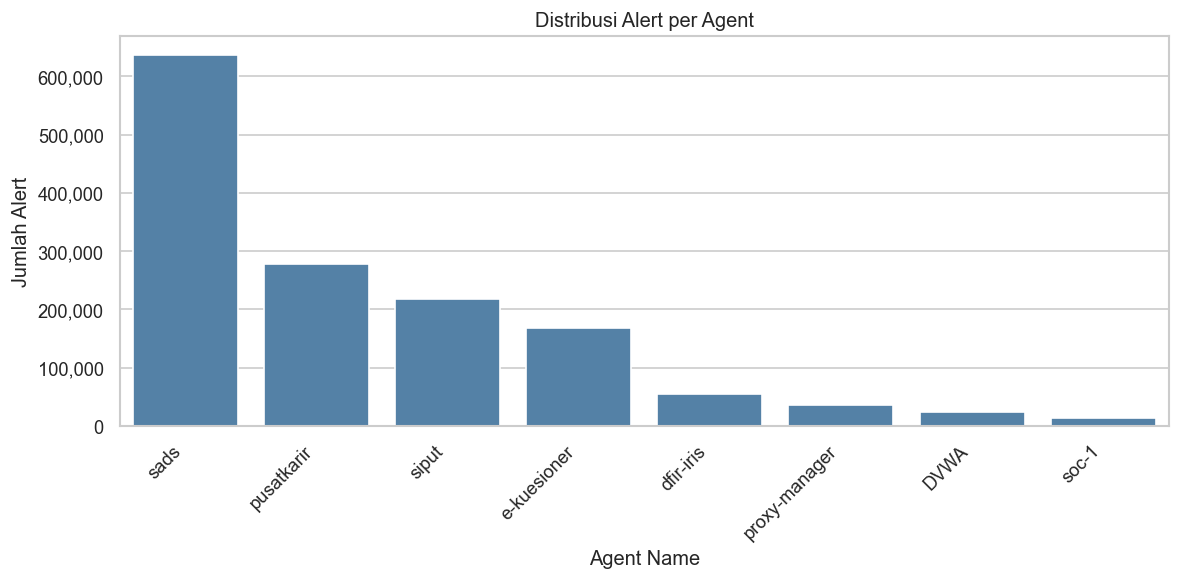

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=agent_dist, x="agent_name", y="alert_count", ax=ax, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Distribusi Alert per Agent")
ax.set_xlabel("Agent Name")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_agent.png", dpi=150)
plt.show()

### 5.2 Distribusi Rule Level (`rule_level`)

In [40]:
level_dist = (
    df.groupby("rule_level")
    .size()
    .reset_index(name="alert_count")
    .sort_values("rule_level")
)
print("Distribusi alert per rule_level:")
print(level_dist.to_string(index=False))

Distribusi alert per rule_level:
 rule_level  alert_count
          3       115792
          4          165
          5       958414
          6         4597
          7       232595
          8          263
          9        12067
         10        60019
         11           33
         12        45227
         13           59
         15          163


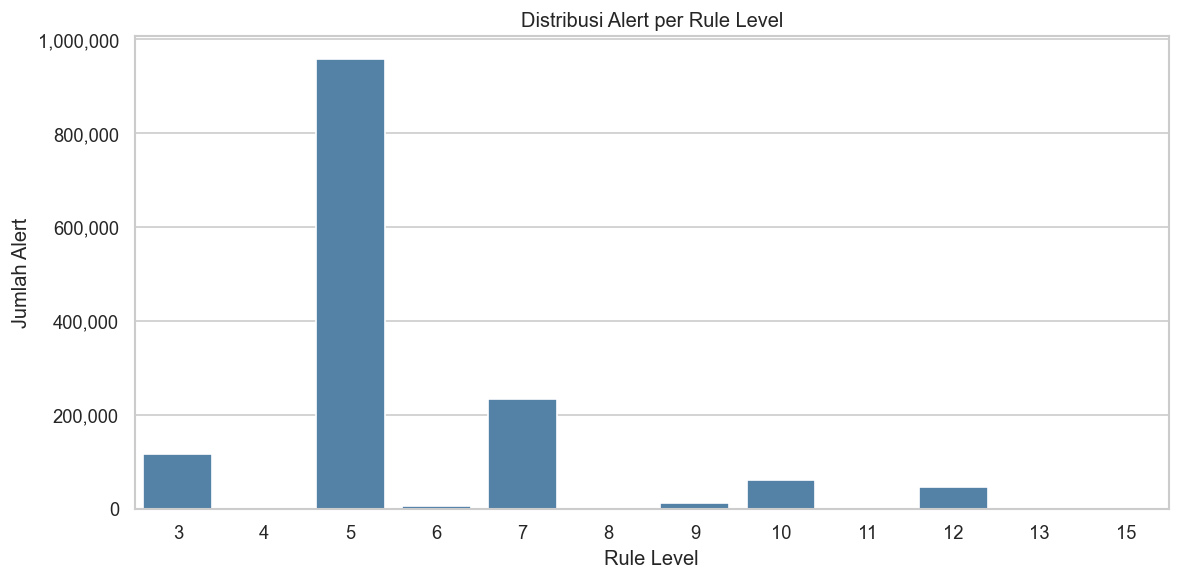

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=level_dist, x="rule_level", y="alert_count", ax=ax, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Distribusi Alert per Rule Level")
ax.set_xlabel("Rule Level")
ax.set_ylabel("Jumlah Alert")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_rule_level.png", dpi=150)
plt.show()

### 5.3 Distribusi Top 10 Rule ID (`rule_id`)

In [42]:
rule_dist = (
    df.groupby("rule_id")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Top 10 Rule ID pemicu alert terbanyak:")
print(rule_dist.head(10).to_string(index=False))

Top 10 Rule ID pemicu alert terbanyak:
rule_id  alert_count
  31122       460177
  31101       445232
    510       147638
    553        49148
 500554        41075
  31120        37981
  23502        30387
  31151        27763
  31162        25874
  31301        21439


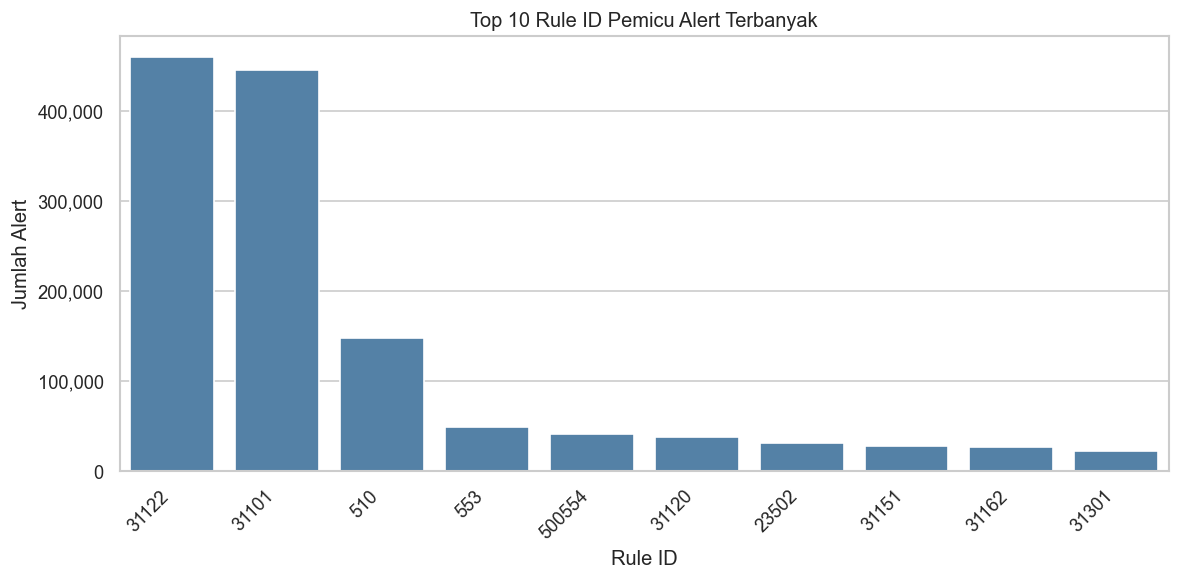

In [43]:
top10_rules = rule_dist.head(10).copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=top10_rules, x="rule_id", y="alert_count",
    ax=ax, color="steelblue", order=top10_rules["rule_id"]
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Top 10 Rule ID Pemicu Alert Terbanyak")
ax.set_xlabel("Rule ID")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top10_rule_id.png", dpi=150)
plt.show()

### 5.4 Distribusi Decoder (`decoder_name`)

In [44]:
decoder_dist = (
    df.groupby("decoder_name")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Top 15 decoder:")
print(decoder_dist.head(15).to_string(index=False))

Top 15 decoder:
              decoder_name  alert_count
             web-accesslog      1008256
                 rootcheck       147671
                      json        59212
          syscheck_deleted        48754
        syscheck_new_entry        43036
            nginx-errorlog        28066
syscheck_integrity_changed        18304
                 freshclam        17764
                    auditd        14548
                     wazuh        12037
              dpkg-decoder         9009
                       pam         6571
                      sshd         4928
                     ossec         3472
                   systemd         2905


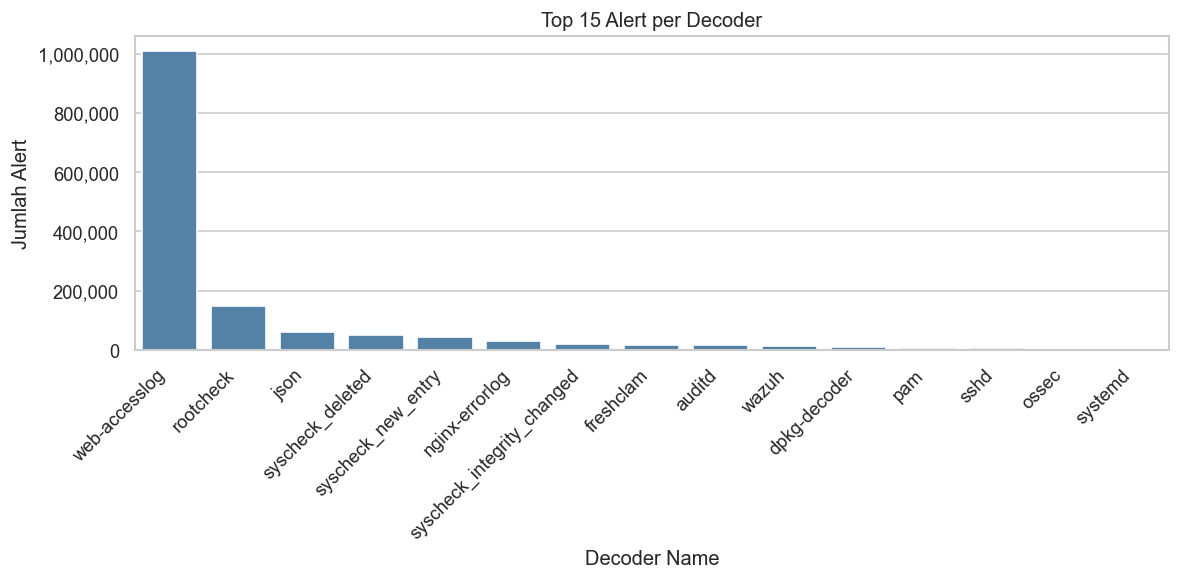

In [45]:
top_decoder = decoder_dist.head(15)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=top_decoder, x="decoder_name", y="alert_count",
    ax=ax, color="steelblue", order=top_decoder["decoder_name"]
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Top 15 Alert per Decoder")
ax.set_xlabel("Decoder Name")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_decoder.png", dpi=150)
plt.show()

### 5.5 Distribusi Lokasi Sumber Log (`location`)

In [46]:
location_dist = (
    df.groupby("location")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Top 15 location:")
print(location_dist.head(15).to_string(index=False))

Top 15 location:
                   location  alert_count
  /var/log/nginx/access.log      1008160
                  rootcheck       147671
                   syscheck       110094
     vulnerability-detector        57766
                   journald        34887
   /var/log/nginx/error.log        28066
   /var/log/audit/audit.log        14548
                wazuh-agent        12108
          /var/log/dpkg.log         9009
               logcollector         3017
                        sca         2136
                 virustotal         1446
             wazuh-monitord          230
    netstat listening ports           95
/var/log/apache2/access.log           93


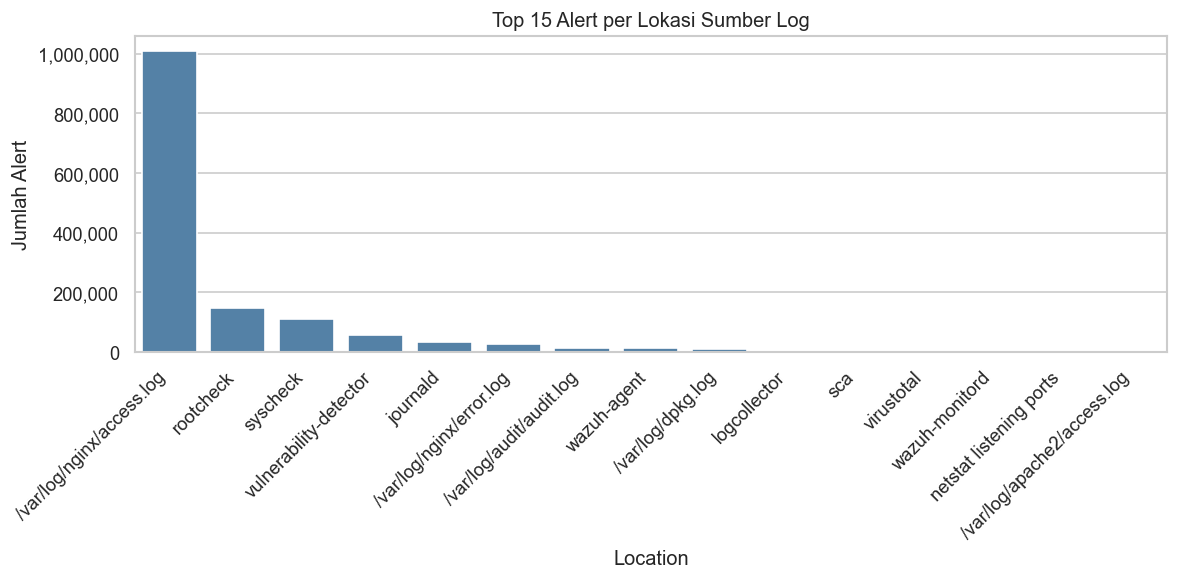

In [47]:
top_location = location_dist.head(15)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=top_location, x="location", y="alert_count",
    ax=ax, color="steelblue", order=top_location["location"]
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Top 15 Alert per Lokasi Sumber Log")
ax.set_xlabel("Location")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_location.png", dpi=150)
plt.show()

### 5.6 Distribusi Top 10 Rule Description (`rule_description`)

In [48]:
desc_dist = (
    df.groupby("rule_description")
    .size()
    .reset_index(name="alert_count")
    .sort_values("alert_count", ascending=False)
)
print("Top 10 Rule Description pemicu alert terbanyak:")
print(desc_dist.head(10).to_string(index=False))

Top 10 Rule Description pemicu alert terbanyak:
                                        rule_description  alert_count
             Web server 500 error code (Internal Error).       460177
                              Web server 400 error code.       445232
         Host-based anomaly detection event (rootcheck).       147638
                                           File deleted.        49148
               Web server 500 error code (server error).        37981
Multiple web server 400 error codes from same source ip.        27763
    Multiple web server 500 error code (Internal Error).        25874
                                    Nginx error message.        21439
                             Integrity checksum changed.        18046
                                  ClamAV database update        17764


### 5.7 Distribusi Rule Groups (`rule_groups`)

Top 15 rule group:
rule_groups
web                       1033056
accesslog                 1000479
system_error               486051
attack                     466405
ossec                      261113
rootcheck                  147671
syscheck                   110008
syscheck_file              109822
vulnerability-detector      57765
syscheck_entry_deleted      49148
syscheck_entry_added        42627
recon                       27763
web_scan                    27763
syslog                      21627
nginx                       21439


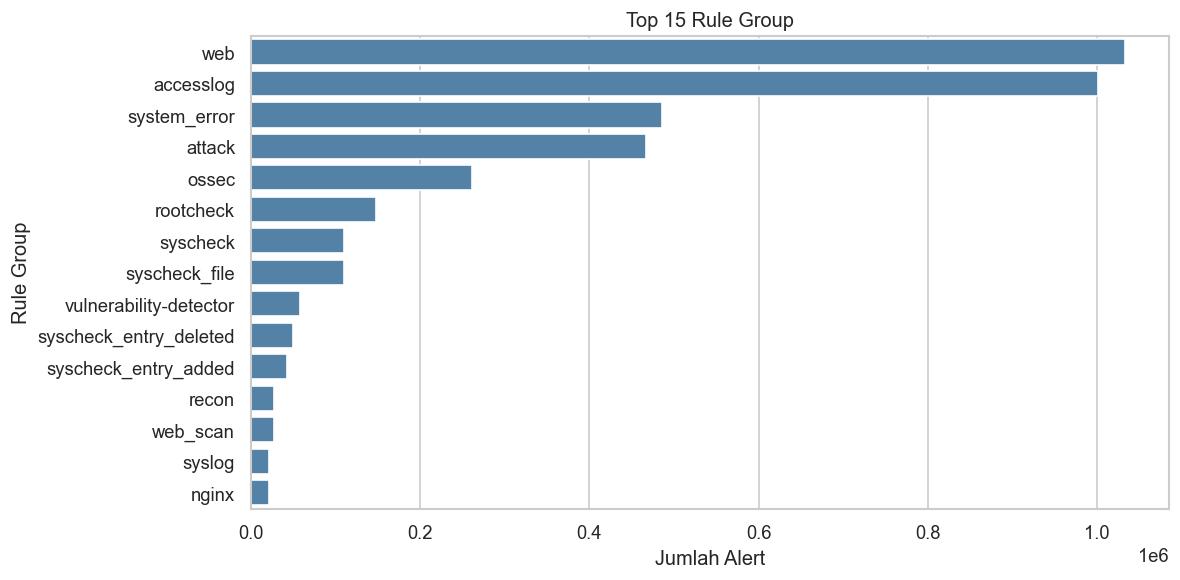

In [49]:
groups = df["rule_groups"].str.split(",").explode().value_counts().head(15)
print("Top 15 rule group:")
print(groups.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=groups.values, y=groups.index, ax=ax, color="steelblue")
ax.set_title("Top 15 Rule Group")
ax.set_xlabel("Jumlah Alert")
ax.set_ylabel("Rule Group")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_rule_groups.png", dpi=150)
plt.show()

### 5.8 Agent × Rule Level

Bukti bahwa `agent_name` dapat dikeluarkan dari fitur clustering (agnostik infrastruktur).

In [50]:
pd.crosstab(df["agent_name"], df["rule_level"])

rule_level,3,4,5,6,7,8,9,10,11,12,13,15
agent_name,,,,,,,,,,,,
DVWA,13459,7,4424,6,4052,257,0,1473,1,120,12,21
dfir-iris,42928,17,1547,0,7509,1,27,2262,0,488,47,21
e-kuesioner,1573,11,125310,1552,29293,0,3,10861,1,238,0,0
proxy-manager,4379,7,29,0,31327,0,28,1,30,0,0,0
pusatkarir,2454,16,128877,504,96061,0,11,8733,0,41040,0,121
sads,31667,61,535253,2174,29300,0,11937,24095,0,2595,0,0
siput,9853,26,161843,361,32395,2,38,12571,0,742,0,0
soc-1,9479,20,1131,0,2658,3,23,23,1,4,0,0


## 6. Eksplorasi Temporal

### 6.1 Distribusi Alert per Hari

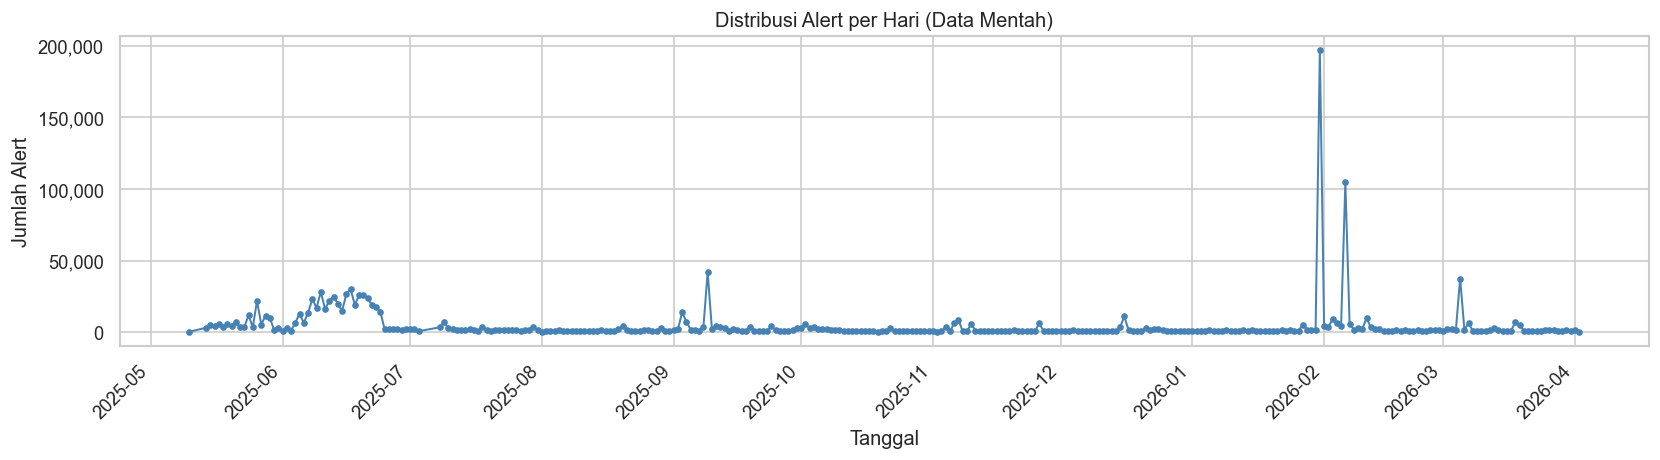

In [51]:
df["_date"] = df["timestamp"].dt.date
daily = df.groupby("_date").size().reset_index(name="alert_count")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily["_date"], daily["alert_count"], marker="o", markersize=3, linewidth=1.2, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Distribusi Alert per Hari (Data Mentah)")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_harian_raw.png", dpi=150)
plt.show()

### 6.2 Distribusi Alert per Jam

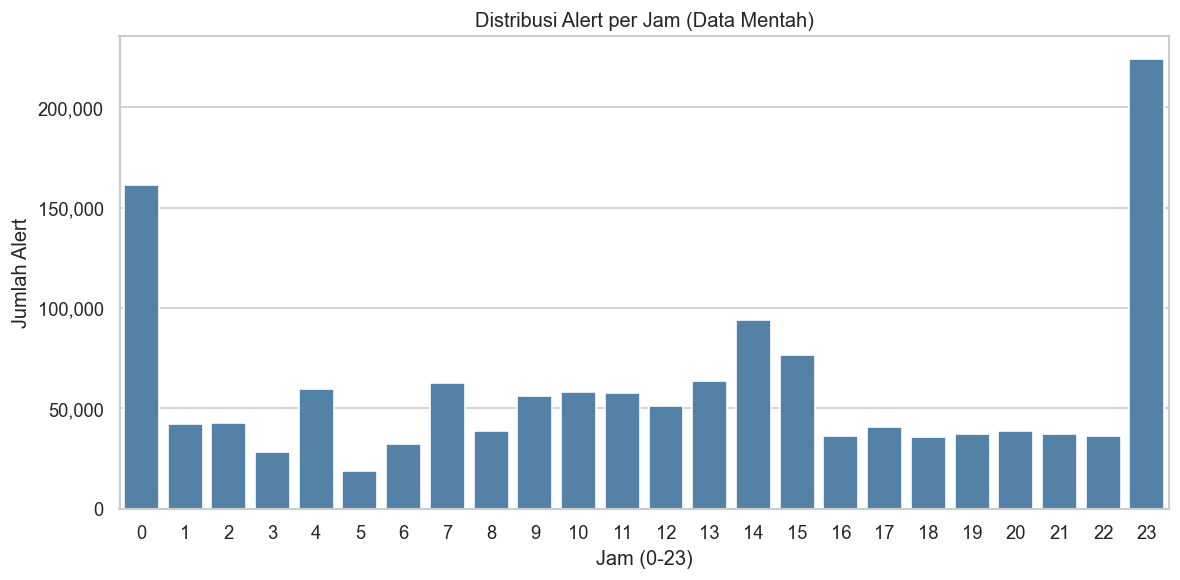

In [52]:
df["_hour"] = df["timestamp"].dt.hour
hourly = df.groupby("_hour").size().reset_index(name="alert_count")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=hourly, x="_hour", y="alert_count", ax=ax, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Distribusi Alert per Jam (Data Mentah)")
ax.set_xlabel("Jam (0-23)")
ax.set_ylabel("Jumlah Alert")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_jam_raw.png", dpi=150)
plt.show()

### 6.3 Distribusi per Bulan

In [53]:
df["_month"] = df["timestamp"].dt.to_period("M").astype(str)
monthly = (
    df.groupby("_month")
    .size()
    .reset_index(name="alert_count")
    .sort_values("_month")
)
print("Jumlah alert per bulan:")
print(monthly.to_string(index=False))

Jumlah alert per bulan:
 _month  alert_count
2025-05       118254
2025-06       428896
2025-07        55577
2025-08        41538
2025-09       119052
2025-10        46411
2025-11        51663
2025-12        50105
2026-01       237854
2026-02       182965
2026-03        95288
2026-04         1791


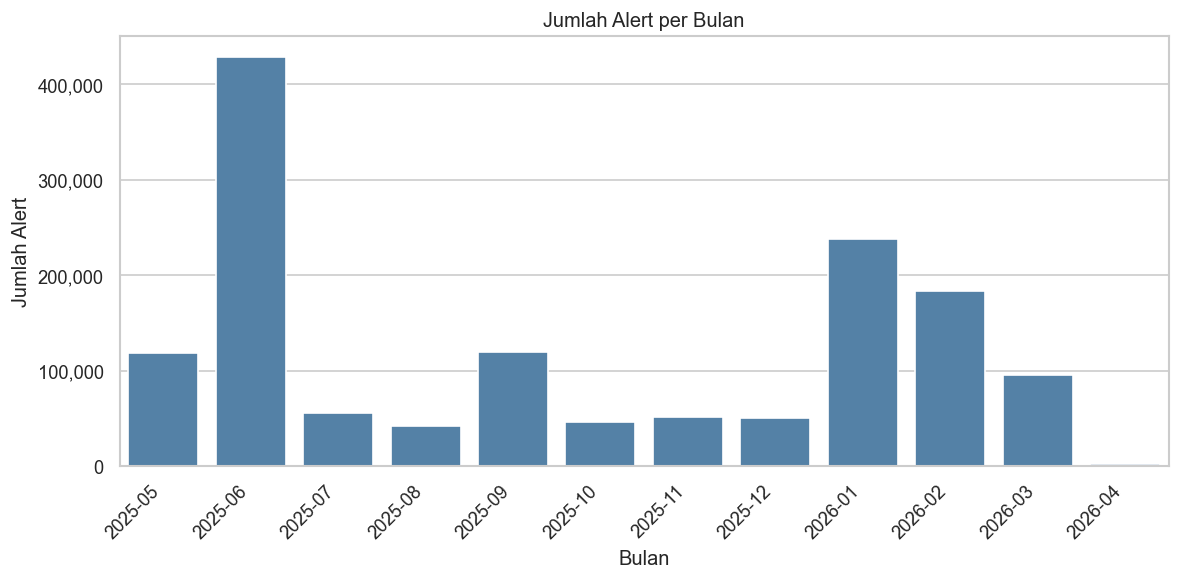

In [54]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=monthly, x="_month", y="alert_count", ax=ax, color="steelblue")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_title("Jumlah Alert per Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah Alert")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tren_alert_per_bulan.png", dpi=150)
plt.show()

In [55]:
print("Jumlah log per bulan:")
display(monthly.set_index("_month"))

print("\nJumlah alert per agen per bulan:")
display(pd.crosstab(df["agent_name"], df["_month"]))

Jumlah log per bulan:


,alert_count
_month,
2025-05,118254
2025-06,428896
2025-07,55577
2025-08,41538
2025-09,119052
2025-10,46411
2025-11,51663
2025-12,50105
2026-01,237854



Jumlah alert per agen per bulan:


_month,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
agent_name,,,,,,,,,,,,
DVWA,0,0,0,0,0,0,5742,7489,437,8235,1837,92
dfir-iris,3524,2552,6389,4545,5945,5544,7433,4822,2077,9464,2447,105
e-kuesioner,0,74996,2950,3184,3255,3212,5080,3269,62523,6276,3913,184
proxy-manager,2048,3669,3081,3551,3556,3018,2866,3231,3603,2922,4150,106
pusatkarir,107074,66053,19852,16974,10465,17280,3259,11286,9828,7093,8362,291
sads,0,276657,18814,9151,91435,12547,20945,13543,18207,143462,31576,745
siput,3962,4606,3931,3888,4098,4415,4486,4430,139434,3691,40727,163
soc-1,1646,363,560,245,298,395,1852,2035,1745,1822,2276,105


In [60]:
df["_month"] = df["timestamp"].dt.to_period("M").astype(str)

TARGET = ["sads", "siput", "pusatkarir", "e-kuesioner"]  # sesuaikan dengan keputusan blacklist
d = df[df["agent_name"].isin(TARGET)]

per_bulan = d.groupby("_month").agg(
    total=("rule_id", "size"),
    rule_unik=("rule_id", "nunique"),
    decoder_unik=("decoder_name", "nunique"),
)
per_bulan["rule_teratas_%"] = d.groupby("_month")["rule_id"].agg(
    lambda s: round(s.value_counts(normalize=True).iloc[0] * 100, 1)
)
per_bulan

,total,rule_unik,decoder_unik,rule_teratas_%
_month,,,,
2025-05,111036,47,18,73.2
2025-06,422312,50,16,83.3
2025-07,45547,34,13,31.3
2025-08,33197,29,13,35.2
2025-09,109253,39,15,76.8
2025-10,37454,34,10,42.7
2025-11,33770,30,9,35.0
2025-12,32528,43,15,36.6
2026-01,229992,34,13,81.9


In [61]:
df["_month"] = df["timestamp"].dt.to_period("M").astype(str)

df[df.duplicated()].groupby(["_month", "agent_name"]).size().sort_values(ascending=False).head(10)

_month   agent_name 
2026-01  siput          71632
2025-06  sads           46462
2026-01  e-kuesioner    26676
2025-05  pusatkarir     12832
2025-06  e-kuesioner    11551
2026-02  sads           11548
2025-06  pusatkarir      7625
2025-09  sads            7237
2026-03  siput           4105
2025-11  sads            2796
dtype: int64

In [62]:
from config import CLUSTER_FEATURES
from src.transformers import apply_feature_engineering, deduplicate

TARGET = ["sads", "siput", "pusatkarir", "e-kuesioner"]
d = df[df["agent_name"].isin(TARGET)].copy()
d["_month"] = d["timestamp"].dt.to_period("M").astype(str)

rows = []
for m, g in d.groupby("_month"):
    dd = deduplicate(apply_feature_engineering(g))
    rows.append({
        "bulan": m,
        "log_mentah": len(g),
        "pola_setelah_dedup": len(dd),
        "reduksi_%": round((1 - len(dd) / len(g)) * 100, 1),
        "kombinasi_fitur_unik": len(dd[CLUSTER_FEATURES].drop_duplicates()),
    })
pd.DataFrame(rows).set_index("bulan")

,log_mentah,pola_setelah_dedup,reduksi_%,kombinasi_fitur_unik
bulan,,,,
2025-05,111036,4940,95.6,136
2025-06,422312,14155,96.6,138
2025-07,45547,5983,86.9,110
2025-08,33197,4490,86.5,92
2025-09,109253,6701,93.9,112
2025-10,37454,6691,82.1,92
2025-11,33770,3393,90.0,86
2025-12,32528,4978,84.7,114
2026-01,229992,7242,96.9,98


In [63]:
cols = [c for c in df.columns if not c.startswith("_")]
sizes = df.groupby(cols).size()
print(sizes[sizes > 1].value_counts().sort_index().head(10).to_string())

2     76973
3     24624
4     14113
5      7580
6      3868
7      1637
8       464
9        87
10       29
11       16


In [64]:
from config import CLUSTER_FEATURES
from src.transformers import apply_feature_engineering, deduplicate

TARGET = ["sads", "siput", "pusatkarir", "e-kuesioner"]
d = df[df["agent_name"].isin(TARGET)].copy()
d["_month"] = d["timestamp"].dt.to_period("M").astype(str)

months = ["2025-06", "2026-01", "2026-02", "2026-03"]
dd = {m: deduplicate(apply_feature_engineering(d[d["_month"] == m])) for m in months}
combos = {m: set(map(tuple, dd[m][CLUSTER_FEATURES].astype(str).values)) for m in months}
rules = {m: set(dd[m]["rule_id"].astype(str)) for m in months}

rows = []
for tr in months:
    for te in months:
        if tr == te:
            continue
        te_feat = dd[te][CLUSTER_FEATURES].astype(str)
        rows.append({
            "latih": tr,
            "uji": te,
            "rule_dikenal_%": round(te_feat["rule_id"].isin(rules[tr]).mean() * 100, 1),
            "kombinasi_dikenal_%": round(
                pd.Series([tuple(r) in combos[tr] for r in te_feat.values]).mean() * 100, 1
            ),
        })
pd.DataFrame(rows)

,latih,uji,rule_dikenal_%,kombinasi_dikenal_%
0,2025-06,2026-01,99.6,98.5
1,2025-06,2026-02,99.1,97.9
2,2025-06,2026-03,97.3,95.4
3,2026-01,2025-06,55.2,55.0
4,2026-01,2026-02,99.8,99.1
5,2026-01,2026-03,98.9,96.8
6,2026-02,2025-06,55.3,55.1
7,2026-02,2026-01,100.0,99.7
8,2026-02,2026-03,99.1,97.7
9,2026-03,2025-06,56.0,55.3


In [65]:
TARGET = ["sads", "siput", "pusatkarir", "e-kuesioner"]
d = df[df["agent_name"].isin(TARGET)].copy()
d["_month"] = d["timestamp"].dt.to_period("M").astype(str)

r2026 = set(d.loc[d["_month"].isin(["2026-01", "2026-02", "2026-03"]), "rule_id"])
jun = d[d["_month"] == "2025-06"]
only_jun = jun[~jun["rule_id"].isin(r2026)]

print(f"Rule hanya di Juni 2025: {only_jun['rule_id'].nunique()} dari {jun['rule_id'].nunique()}")
(only_jun.groupby(["agent_name", "rule_id", "rule_description", "rule_level"])
    .size().reset_index(name="log_mentah")
    .sort_values("log_mentah", ascending=False)
    .head(20))

Rule hanya di Juni 2025: 8 dari 50


,agent_name,rule_id,rule_description,rule_level,log_mentah
420,sads,31101,Web server 400 error code.,5,253305
207,e-kuesioner,31101,Web server 400 error code.,5,66629
210,pusatkarir,31101,Web server 400 error code.,5,31375
422,sads,31151,Multiple web server 400 error codes from same ...,10,13881
212,pusatkarir,553,File deleted.,7,13501
208,e-kuesioner,31151,Multiple web server 400 error codes from same ...,10,4876
211,pusatkarir,31151,Multiple web server 400 error codes from same ...,10,2311
424,siput,31101,Web server 400 error code.,5,559
2,e-kuesioner,19007,CIS Ubuntu Linux 22.04 LTS Benchmark v2.0.0.: ...,7,1
3,e-kuesioner,19007,CIS Ubuntu Linux 22.04 LTS Benchmark v2.0.0.: ...,7,1


In [66]:
TARGET = ["sads", "siput", "pusatkarir", "e-kuesioner"]
d = df[df["agent_name"].isin(TARGET)].copy()
d["_month"] = d["timestamp"].dt.to_period("M").astype(str)

web = d[d["rule_groups"].str.contains("web|attack|recon", case=False, regex=True)]
hi = d[d["rule_level"] >= 10]

ringkas = pd.DataFrame({
    "log_web": web.groupby("_month").size(),
    "rule_web_unik": web.groupby("_month")["rule_id"].nunique(),
    "log_level>=10": hi.groupby("_month").size(),
    "rule_level>=10_unik": hi.groupby("_month")["rule_id"].nunique(),
}).fillna(0).astype(int)
display(ringkas)

q1 = web[web["_month"].isin(["2026-01", "2026-02", "2026-03"])]
q1.groupby(["rule_id", "rule_description", "rule_level"]).size().sort_values(ascending=False).head(10)

,log_web,rule_web_unik,log_level>=10,rule_level>=10_unik
_month,,,,
2025-05,87532,9,12619,4
2025-06,380033,16,34749,5
2025-07,16023,13,3934,5
2025-08,5563,13,25,3
2025-09,89587,13,3584,4
2025-10,22434,14,269,4
2025-11,20070,18,4320,8
2025-12,10191,18,4342,9
2026-01,208705,13,20443,6


rule_id  rule_description                                                      rule_level
31122    Web server 500 error code (Internal Error).                           5             324632
31120    Web server 500 error code (server error).                             5              37706
31162    Multiple web server 500 error code (Internal Error).                  10             21692
31301    Nginx error message.                                                  3              16512
31533    High amount of POST requests in a small period of time (likely bot).  10              1014
31104    Common web attack.                                                    6                623
100105   Possible directory traversal attempt                                  10               342
31516    Suspicious URL access.                                                6                322
31103    SQL injection attempt.                                                7                234
100103   P

### 6.4 Heatmap Alert: Hari × Jam

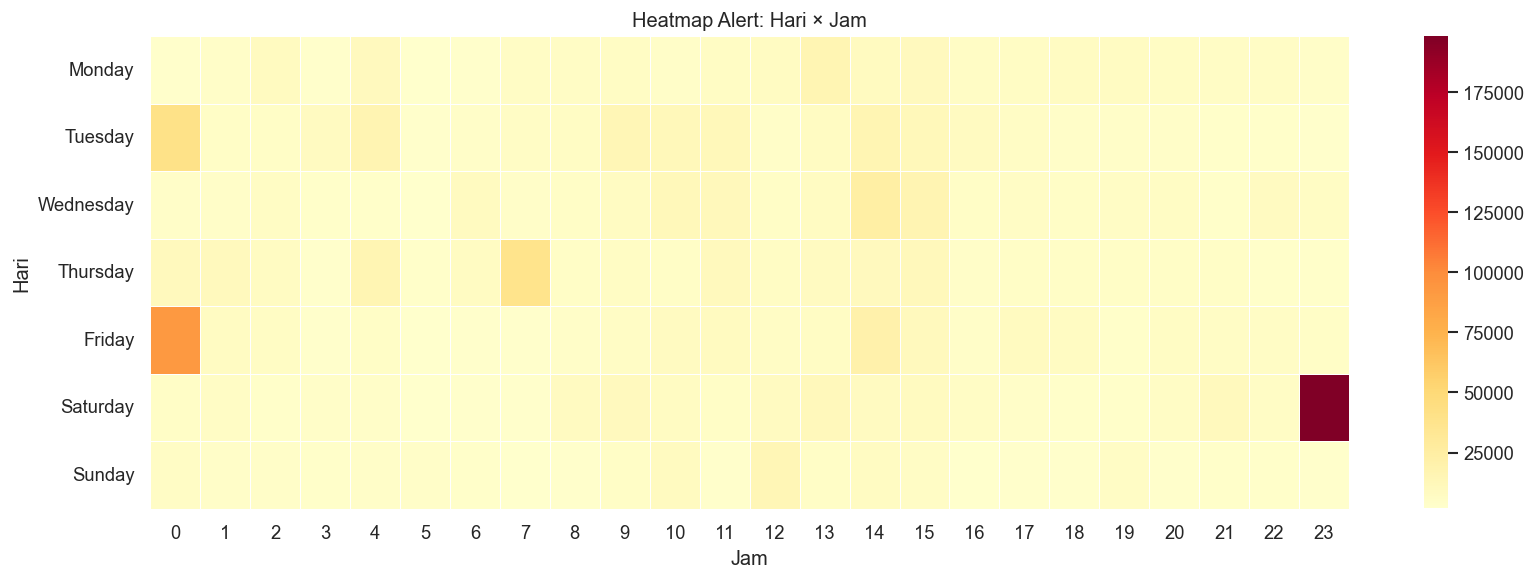

In [56]:
df["_weekday"] = df["timestamp"].dt.day_name()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pivot = df.pivot_table(index="_weekday", columns="_hour", aggfunc="size", fill_value=0)
pivot = pivot.reindex(day_order)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot, cmap="YlOrRd", annot=False, linewidths=0.3, ax=ax)
ax.set_title("Heatmap Alert: Hari × Jam")
ax.set_xlabel("Jam")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "heatmap_hari_jam.png", dpi=150)
plt.show()

## 7. Ringkasan Temuan Data Understanding

In [57]:
df.drop(columns=["_date", "_hour", "_month", "_weekday"], inplace=True, errors="ignore")

print("=" * 60)
print("RINGKASAN DATA UNDERSTANDING")
print("=" * 60)
print(f"Total record mentah              : {len(raw_records):,}")
print(f"Total record setelah cleaning    : {len(df):,}")
print(f"Record tereliminasi              : {rows_removed:,} ({pct_removed:.2f}%)")
print(f"Jumlah kolom                     : {len(df.columns)}")
print(f"Kolom                            : {list(df.columns)}")
print(f"Null values setelah cleaning     : {df.isnull().sum().sum()}")
print(f"Duplikat persis                  : {n_exact_dup:,}")
print(f"Jumlah agent unik                : {df['agent_name'].nunique()}")
print(f"Jumlah rule_id unik              : {df['rule_id'].nunique()}")
print(f"Jumlah decoder unik              : {df['decoder_name'].nunique()}")
print(f"Rentang waktu                    : {df['timestamp'].min()} s.d. {df['timestamp'].max()}")
print("=" * 60)
print()
print("✓ Fase Data Understanding selesai.")
print("  Lanjutkan ke notebook 02_data-preparation.ipynb.")

RINGKASAN DATA UNDERSTANDING
Total record mentah              : 1,430,776
Total record setelah cleaning    : 1,429,394
Record tereliminasi              : 1,382 (0.10%)
Jumlah kolom                     : 8
Kolom                            : ['timestamp', 'agent_name', 'rule_level', 'rule_description', 'rule_id', 'rule_groups', 'decoder_name', 'location']
Null values setelah cleaning     : 0
Duplikat persis                  : 232,476
Jumlah agent unik                : 8
Jumlah rule_id unik              : 113
Jumlah decoder unik              : 24
Rentang waktu                    : 2025-05-10 10:06:46.854000 s.d. 2026-04-02 07:59:05.013000

✓ Fase Data Understanding selesai.
  Lanjutkan ke notebook 02_data-preparation.ipynb.
